In [1]:
# ============================================================
#  Project 4: Statistical Analysis — A/B Testing & Segmentation
# ============================================================

# Step 1: Load & Explore Data
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
data = pd.read_csv("C:/Users/krishna/Downloads/archive (6)/ab_data.csv")

# Preview data
data.head()


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


group
treatment    147276
control      147202
Name: count, dtype: int64


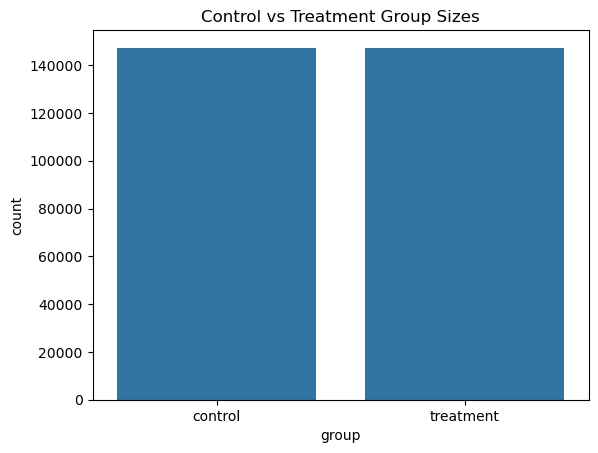

In [2]:
# Check group sizes
print(data['group'].value_counts())

# Visualize balance
sns.countplot(x='group', data=data)
plt.title("Control vs Treatment Group Sizes")
plt.show()


Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted'], dtype='object')
T-statistic: 1.2369207675839398
P-value: 0.21611748562490826


C:\Users\krishna\AppData\Local\Temp\ipykernel_9620\1249227260.py:19: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='group', y='converted', data=data, ci=None)


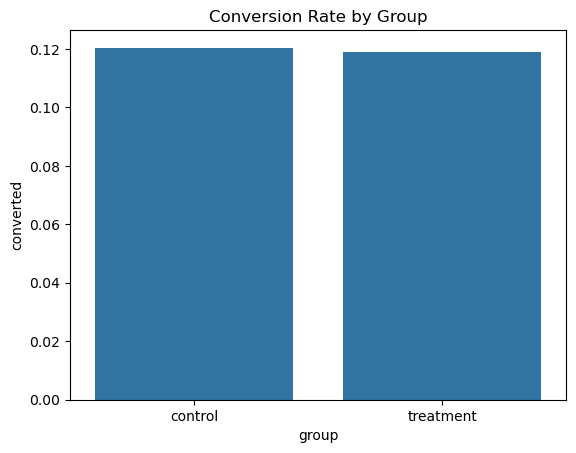

In [3]:
# Step 2: Hypothesis Testing
# (a) T-Test — Revenue Difference
from scipy import stats

# Check actual column names first
print(data.columns)

# Use 'group' instead of 'variant'
control = data[data['group'] == 'control']['converted']
treatment = data[data['group'] == 'treatment']['converted']

# Perform t-test
t_stat, p_val = stats.ttest_ind(control, treatment)

print("T-statistic:", t_stat)
print("P-value:", p_val)

# Visualize conversion rates
sns.barplot(x='group', y='converted', data=data, ci=None)
plt.title("Conversion Rate by Group")
plt.show()


In [4]:
# (b) Chi-Square — Conversion Rate
# Build contingency table
contingency = pd.crosstab(data['group'], data['converted'])

# Run Chi-Square test
chi2, p_val, dof, exp = stats.chi2_contingency(contingency)
print(f"Chi2: {chi2:.4f}, P-value: {p_val:.4f}")

# Calculate conversion rates
control_cr = data[data['group'] == 'control']['converted'].mean()
treatment_cr = data[data['group'] == 'treatment']['converted'].mean()
print(f"Control CR: {control_cr:.2%}, Treatment CR: {treatment_cr:.2%}")


Chi2: 1.5160, P-value: 0.2182
Control CR: 12.04%, Treatment CR: 11.89%


In [5]:
# (c) Confidence Interval Example
from scipy.stats import t as t_dist

n = len(control)
mean = control.mean()
std = control.std()
se = std / np.sqrt(n)

ci = t_dist.interval(0.95, n-1, loc=mean, scale=se)
print(f"95% CI for Control Revenue: {ci}")


95% CI for Control Revenue: (np.float64(0.11873672068528361), np.float64(0.1220616380326686))


In [6]:
# (d) Effect Size — Cohen’s d
pooled_std = np.sqrt((control.std()**2 + treatment.std()**2)/2)
cohens_d = (treatment.mean() - control.mean()) / pooled_std
print(f"Cohen's d: {cohens_d:.4f}")


Cohen's d: -0.0046


In [7]:
# Step 3: Customer Segmentation (Clustering)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Select features (converted + group encoded)
features = data[['converted']].copy()
features['group_encoded'] = data['group'].map({'control':0, 'treatment':1})

# Scale
scaled = StandardScaler().fit_transform(features)

# Apply PCA (optional)
pca = PCA(n_components=2)
reduced = pca.fit_transform(scaled)

# Apply KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(reduced)

data['cluster'] = labels
print(data[['user_id','group','converted','cluster']].head())


   user_id      group  converted  cluster
0   851104    control          0        0
1   804228    control          0        0
2   661590  treatment          0        0
3   853541  treatment          0        0
4   864975    control          1        1
